In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import HTML, display, Image
from base64 import b64encode

In [2]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

if len(uploaded_names) == 0:
  raise Exception("No File Uploaded")

video_name = uploaded_names[0]
video_path = '/content/' + video_name

print('Input Video:', video_name)

Saving blue-track.mp4 to blue-track.mp4
Input Video: blue-track.mp4


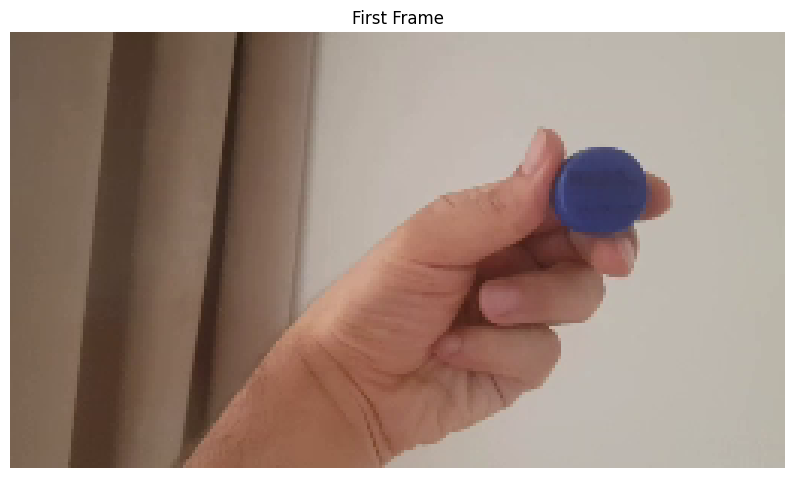

In [4]:
capture = cv2.VideoCapture(video_path)
success, first_frame = capture.read()

if not success:
  raise ValueError('The First Video Frame Could Not Be Read')

first_frame_rgb = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))

plt.imshow(first_frame_rgb)
plt.title('First Frame')
plt.axis('off')

plt.show()

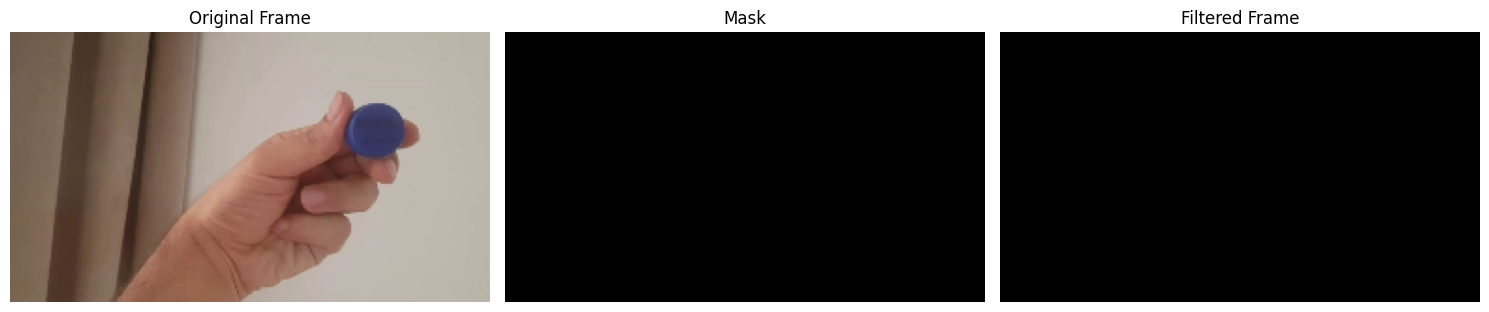

In [5]:
lower_color = np.array([35, 70, 50], dtype=np.uint8)
upper_color = np.array([85, 255, 255], dtype=np.uint8)

hsv_frame = cv2.cvtColor(first_frame, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv_frame, lower_color, upper_color)
filtered_frame = cv2.bitwise_and(first_frame, first_frame, mask=mask)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(first_frame_rgb)
plt.title('Original Frame')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title('Mask')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(filtered_frame, cv2.COLOR_BGR2RGB))
plt.title('Filtered Frame')
plt.axis('off')

plt.tight_layout()
plt.show()

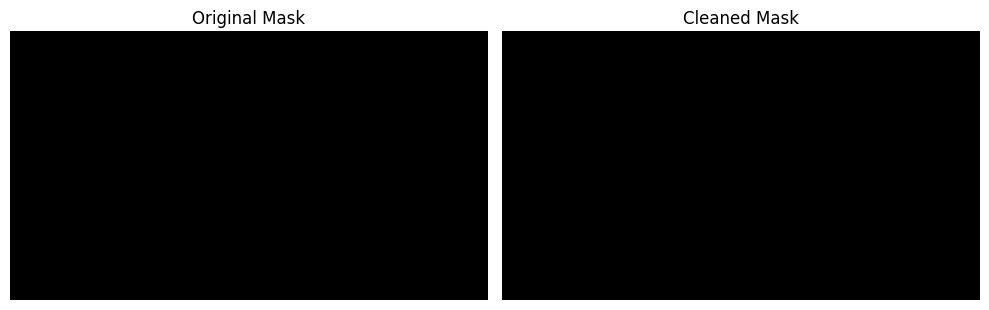

In [6]:
kernel = np.ones((5, 5), np.uint8)
clean_mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(mask, cmap='gray')
plt.title('Original Mask')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(clean_mask, cmap='gray')
plt.title('Cleaned Mask')
plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
capture = cv2.VideoCapture(video_path)

if not capture.isOpened():
  raise ValueError('The Video Could Not Be Opened')

frame_width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = capture.get(cv2.CAP_PROP_FPS)

if fps <= 0:
  fps = 25.0

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
output_path = '/content/output_video.mp4'
output_video = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

frame_count = 0

while True:
  success, frame = capture.read()

  if not success:
    break

  hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
  mask = cv2.inRange(hsv_frame, lower_color, upper_color)
  clean_mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
  clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

  filtered_frame = cv2.bitwise_and(frame, frame, mask=clean_mask)

  output_video.write(filtered_frame)
  frame_count += 1

capture.release()
output_video.release()

print('Output Video Saved:', output_path)

Output Video Saved: /content/output_video.mp4


In [8]:
video_bytes = open(output_path, 'rb').read()
video_base64 = b64encode(video_bytes).decode()

display(HTML(
    f'''
    <video width=720 controls>
        <source src="data:video/mp4;base64,{video_base64}"
                type="video/mp4">
    </video>
    '''
))

In [9]:
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>